### Model 02: Expected Available Quantity Forecast

This notebook provides a structured pipeline for loading, cleaning, visualizing, and forecasting the weekly export volumes of frozen farmed salmon using classical baselines and LightGBM.

We trained a LightGBM regressor with early stopping and evaluated model performance against multiple historical and seasonal baselines.


In [ ]:
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

print("Uploaded:", filename)

Saving Salmon_data.xlsx to Salmon_data.xlsx
Uploaded: Salmon_data.xlsx


In [ ]:
# Read excel via openpyxl

%pip -q install openpyxl

import pandas as pd
from datetime import date
from io import BytesIO

raw = pd.read_excel(
    BytesIO(uploaded[filename]),
    sheet_name="Vekt",
    header=None,
    engine="openpyxl"
)

# Keep weekly observations, excluding headers and footnotes.
is_week = raw[1].astype(str).str.fullmatch(r"\d{4}U\d{2}")

df = raw.loc[is_week, [1, 2, 3]].copy()
df.columns = ["week", "volume_tonnes", "price_nok_kg"]

# Convert ISO week labels into the Monday of each week.
df["date"] = pd.to_datetime(
    df["week"].map(
        lambda w: date.fromisocalendar(
            int(w[:4]), int(w[5:]), 1
        )
    )
)

for col in ["volume_tonnes", "price_nok_kg"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("date").set_index("date")

assert not df.index.duplicated().any(), "Duplicate weeks found"

# Preserve a regular weekly index so shifts always mean weeks.
df = df.asfreq("W-MON")

print("Rows:", len(df))
print("Missing values:")
print(df[["volume_tonnes", "price_nok_kg"]].isna().sum())

display(df.head())
display(df.tail())

Rows: 1397
Missing values:
volume_tonnes    0
price_nok_kg     0
dtype: int64


,week,volume_tonnes,price_nok_kg
date,,,
2000-01-03,2000U01,383,32.54
2000-01-10,2000U02,216,33.63
2000-01-17,2000U03,633,36.06
2000-01-24,2000U04,393,34.27
2000-01-31,2000U05,453,33.91


,week,volume_tonnes,price_nok_kg
date,,,
2026-09-07,2026U37,697,69.77
2026-09-14,2026U38,860,73.09
2026-09-21,2026U39,654,74.68
2026-09-28,2026U40,936,75.31
2026-10-05,2026U41,819,72.12


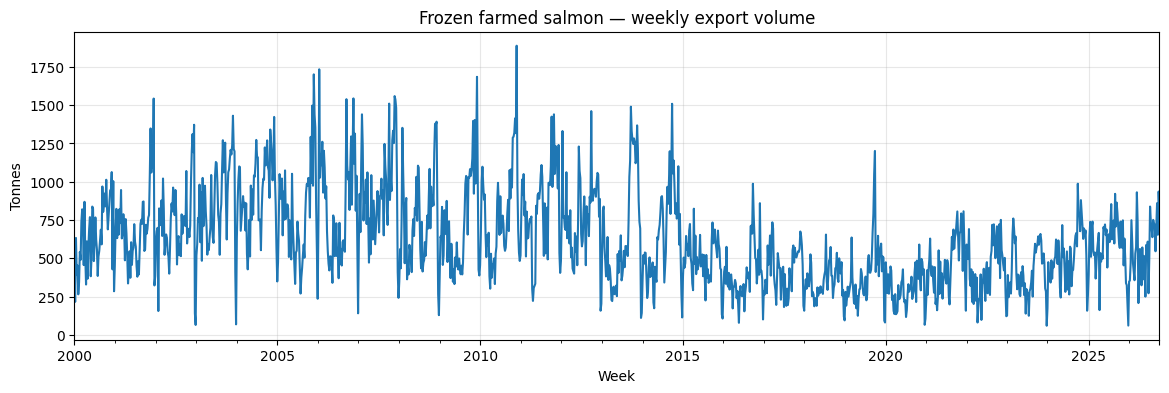

In [ ]:
import matplotlib.pyplot as plt

# This is the weekly export volume according to the xlsx file.

df["volume_tonnes"].plot(figsize=(14, 4))

plt.title("Frozen farmed salmon — weekly export volume")
plt.xlabel("Week")
plt.ylabel("Tonnes")
plt.grid(alpha=0.3)
plt.show()

## 1. Feature Engineering
To support machine learning models, we construct lag features (1, 2, and 4 weeks), rolling mean/standard deviations, lagging price features, and cyclical trigonometric features (`week_sin`, `week_cos`) to capture calendar seasonality.


In [ ]:
import numpy as np
import pandas as pd

quantity_data = df.copy()

for lag in [1, 2, 4]:
    quantity_data[f"volume_lag_{lag}"] = (
        quantity_data["volume_tonnes"].shift(lag)
    )

quantity_data["volume_mean_4"] = (
    quantity_data["volume_tonnes"].shift(1).rolling(4).mean()
)

quantity_data["volume_std_4"] = (
    quantity_data["volume_tonnes"].shift(1).rolling(4).std()
)

quantity_data["price_lag_1"] = (
    quantity_data["price_nok_kg"].shift(1)
)

week_number = quantity_data.index.isocalendar().week.astype(int)
quantity_data["week_sin"] = np.sin(2 * np.pi * week_number / 52.1775)
quantity_data["week_cos"] = np.cos(2 * np.pi * week_number / 52.1775)

quantity_features = [
    "volume_lag_1",
    "volume_lag_2",
    "volume_lag_4",
    "volume_mean_4",
    "volume_std_4",
    "price_lag_1",
    "week_sin",
    "week_cos",
]

quantity_data = quantity_data.dropna(
    subset=quantity_features + ["volume_tonnes"]
)

X_quantity = quantity_data[quantity_features]
y_quantity = quantity_data["volume_tonnes"]

display(X_quantity.head())

,volume_lag_1,volume_lag_2,volume_lag_4,volume_mean_4,volume_std_4,price_lag_1,week_sin,week_cos
date,,,,,,,,
2000-01-31,393.0,633.0,383.0,406.25,171.587441,34.27,0.566372,0.824150
2000-02-07,453.0,393.0,216.0,423.75,171.994913,33.91,0.661275,0.750144
2000-02-14,265.0,453.0,633.0,436.00,152.957510,35.30,0.746600,0.665274
2000-02-21,344.0,265.0,393.0,363.75,79.504193,34.49,0.821111,0.570768
2000-02-28,542.0,344.0,453.0,401.00,121.559313,36.34,0.883731,0.467996


## 2. Sequential Train-Validation-Test Splitting
Since this is chronological time-series data, we split the data sequentially without shuffling. 70% is allocated for training, 15% for validation (hyperparameter optimization), and 15% for testing.


In [ ]:
n = len(quantity_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train_q = X_quantity.iloc[:train_end]
y_train_q = y_quantity.iloc[:train_end]

X_val_q = X_quantity.iloc[train_end:val_end]
y_val_q = y_quantity.iloc[train_end:val_end]

X_test_q = X_quantity.iloc[val_end:]
y_test_q = y_quantity.iloc[val_end:]

for name, part in [
    ("Train", X_train_q),
    ("Validation", X_val_q),
    ("Test", X_test_q),
]:
    print(name, len(part), part.index.min(), part.index.max())

Train 975 2000-01-31 00:00:00 2018-10-01 00:00:00
Validation 209 2018-10-08 00:00:00 2022-10-03 00:00:00
Test 209 2022-10-10 00:00:00 2026-10-05 00:00:00


## 3. Model Training (LightGBM Regressor)
We train a Gradient Boosting decision tree model configured with L1 loss (MAE metric). We employ early stopping on the validation set to avoid overfitting.


In [ ]:
%pip -q install lightgbm

import lightgbm as lgb

quantity_model = lgb.LGBMRegressor(
    objective="regression",
    metric="mae",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=4,
    min_child_samples=30,
    reg_lambda=5,
    verbosity=-1,
    random_state=42,
    n_jobs=-1
)

quantity_model.fit(
    X_train_q,
    y_train_q,
    eval_set=[(X_val_q, y_val_q)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100),
    ],
)

print("Best number of trees:", quantity_model.best_iteration_)

Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 109.392
[200]	valid_0's l1: 103.852
[300]	valid_0's l1: 102.958
Early stopping, best iteration is:
[316]	valid_0's l1: 102.825
Best number of trees: 316


## 4. Model Evaluation
We compute MAE and RMSE metrics for our LightGBM model alongside three distinct baselines: Last-week naive baseline, 4-week rolling average, and historical seasonal average.


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Seasonal baseline: training-only average for each week of the year.
seasonal_means = y_train_q.groupby(
    y_train_q.index.isocalendar().week.astype(int)
).mean()

seasonal_val = pd.Series(
    X_val_q.index.isocalendar().week.astype(int).to_numpy(),
    index=X_val_q.index,
).map(seasonal_means).fillna(y_train_q.mean())

val_pred_q = np.maximum(0, quantity_model.predict(X_val_q))

def quantity_metrics(actual, predicted):
    return {
        "MAE (tonnes)": mean_absolute_error(actual, predicted),
        "RMSE (tonnes)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
    }

validation_results_q = pd.DataFrame({
    "Last-week baseline": quantity_metrics(
        y_val_q, X_val_q["volume_lag_1"]
    ),
    "Four-week average": quantity_metrics(
        y_val_q, X_val_q["volume_mean_4"]
    ),
    "Seasonal average": quantity_metrics(
        y_val_q, seasonal_val
    ),
    "LightGBM": quantity_metrics(y_val_q, val_pred_q),
}).T

display(validation_results_q.round(2))

,MAE (tonnes),RMSE (tonnes)
Last-week baseline,121.15,156.40
Four-week average,115.07,148.30
Seasonal average,320.74,360.22
LightGBM,102.83,130.69


## 5. Test Set Evaluation & Interpreting Results

To confirm our findings, we now run our evaluation pipeline on the remaining **15% unseen test set**. This represents the ultimate measure of our model's performance. We measure "goodness" by how much the LightGBM model reduces error (MAE and RMSE) relative to classical baselines (like predicting last week's volume).

--- Final Evaluation on Test Set ---


,MAE (tonnes),RMSE (tonnes)
Last-week baseline,129.69,162.57
Four-week average,121.48,157.59
Seasonal average,227.30,278.57
LightGBM,111.44,140.90



LightGBM model error is 14.07% lower than the naive last-week baseline on the test set.



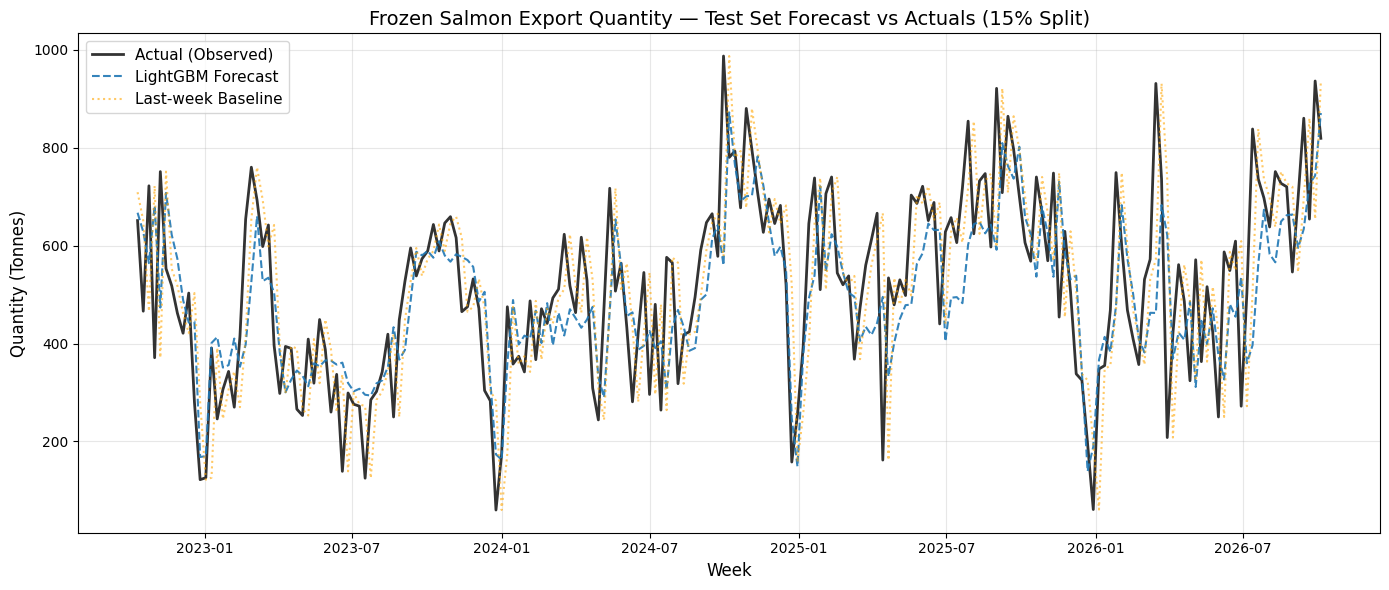

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from datetime import date
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Reload the dataframe since the runtime was reset
raw = pd.read_excel(
    "/content/Salmon_data.xlsx",
    sheet_name="Vekt",
    header=None,
    engine="openpyxl"
)

is_week = raw[1].astype(str).str.fullmatch(r"\d{4}U\d{2}")
df = raw.loc[is_week, [1, 2, 3]].copy()
df.columns = ["week", "volume_tonnes", "price_nok_kg"]

df["date"] = pd.to_datetime(
    df["week"].map(
        lambda w: date.fromisocalendar(int(w[:4]), int(w[5:]), 1)
    )
)

for col in ["volume_tonnes", "price_nok_kg"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.sort_values("date").set_index("date")
df = df.asfreq("W-MON")

# 2. Recreate features on quantity_data
quantity_data = df.copy()

for lag in [1, 2, 4]:
    quantity_data[f"volume_lag_{lag}"] = quantity_data["volume_tonnes"].shift(lag)

quantity_data["volume_mean_4"] = quantity_data["volume_tonnes"].shift(1).rolling(4).mean()
quantity_data["volume_std_4"] = quantity_data["volume_tonnes"].shift(1).rolling(4).std()
quantity_data["price_lag_1"] = quantity_data["price_nok_kg"].shift(1)

week_number = quantity_data.index.isocalendar().week.astype(int)
quantity_data["week_sin"] = np.sin(2 * np.pi * week_number / 52.1775)
quantity_data["week_cos"] = np.cos(2 * np.pi * week_number / 52.1775)

quantity_features = [
    "volume_lag_1", "volume_lag_2", "volume_lag_4",
    "volume_mean_4", "volume_std_4", "price_lag_1",
    "week_sin", "week_cos"
]

quantity_data = quantity_data.dropna(subset=quantity_features + ["volume_tonnes"])
X_quantity = quantity_data[quantity_features]
y_quantity = quantity_data["volume_tonnes"]

# 3. Sequential Train-Validation-Test Splitting (70% - 15% - 15%)
n = len(quantity_data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train_q = X_quantity.iloc[:train_end]
y_train_q = y_quantity.iloc[:train_end]
X_val_q = X_quantity.iloc[train_end:val_end]
y_val_q = y_quantity.iloc[train_end:val_end]
X_test_q = X_quantity.iloc[val_end:]
y_test_q = y_quantity.iloc[val_end:]

# 4. Retrain LightGBM Model
quantity_model = lgb.LGBMRegressor(
    objective="regression",
    metric="mae",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=15,
    max_depth=4,
    min_child_samples=30,
    reg_lambda=5,
    verbosity=-1,
    random_state=42,
    n_jobs=-1
)
quantity_model.fit(
    X_train_q,
    y_train_q,
    eval_set=[(X_val_q, y_val_q)],
    callbacks=[lgb.early_stopping(50, verbose=False)]
)

# 5. Helper Metric Function
def quantity_metrics(actual, predicted):
    return {
        "MAE (tonnes)": mean_absolute_error(actual, predicted),
        "RMSE (tonnes)": np.sqrt(mean_squared_error(actual, predicted)),
    }

# 6. Seasonal baselines mapping
seasonal_means = y_train_q.groupby(y_train_q.index.isocalendar().week.astype(int)).mean()
seasonal_test = pd.Series(
    X_test_q.index.isocalendar().week.astype(int).to_numpy(),
    index=X_test_q.index,
).map(seasonal_means).fillna(y_train_q.mean())

# 7. Predict on Test Set
test_pred_q = np.maximum(0, quantity_model.predict(X_test_q))

test_results_q = pd.DataFrame({
    "Last-week baseline": quantity_metrics(y_test_q, X_test_q["volume_lag_1"]),
    "Four-week average": quantity_metrics(y_test_q, X_test_q["volume_mean_4"]),
    "Seasonal average": quantity_metrics(y_test_q, seasonal_test),
    "LightGBM": quantity_metrics(y_test_q, test_pred_q),
}).T

print("--- Final Evaluation on Test Set ---")
display(test_results_q.round(2))

# Relative reduction in MAE
baseline_mae = test_results_q.loc["Last-week baseline", "MAE (tonnes)"]
model_mae = test_results_q.loc["LightGBM", "MAE (tonnes)"]
improvement = ((baseline_mae - model_mae) / baseline_mae) * 100
print(f"\nLightGBM model error is {improvement:.2f}% lower than the naive last-week baseline on the test set.\n")

# 8. Visualize Test Forecasts
plt.figure(figsize=(14, 6))
plt.plot(y_test_q.index, y_test_q, label="Actual (Observed)", color="black", alpha=0.8, linewidth=2)
plt.plot(y_test_q.index, test_pred_q, label="LightGBM Forecast", color="#1f77b4", linestyle="--", alpha=0.9)
plt.plot(y_test_q.index, X_test_q["volume_lag_1"], label="Last-week Baseline", color="orange", linestyle=":", alpha=0.6)

plt.title("Frozen Salmon Export Quantity — Test Set Forecast vs Actuals (15% Split)", fontsize=14)
plt.ylabel("Quantity (Tonnes)", fontsize=12)
plt.xlabel("Week", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()